HEART DISEASE PREDICTION

Dataset Shape: (920, 16)

First 5 Rows:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



Column Names:
['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Target Column: num

Missing Values:
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

Categorical Columns:
['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

Final Feature Shape: (920, 21)

Training Samples: 736
Testing Samples: 184

Feature Scaling Completed!

LOGISTIC REGRESSION RESULTS
Accuracy : 0.8207
Precision: 0.8108
Recall   : 0.8824

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.74      0.79        82
           1       0.81      0.88      0.85       102

    accuracy                           0.82       184
   macro avg       0.82      0.81      

C:\Users\Hp\AppData\Local\Temp\ipykernel_5832\417878082.py:123: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


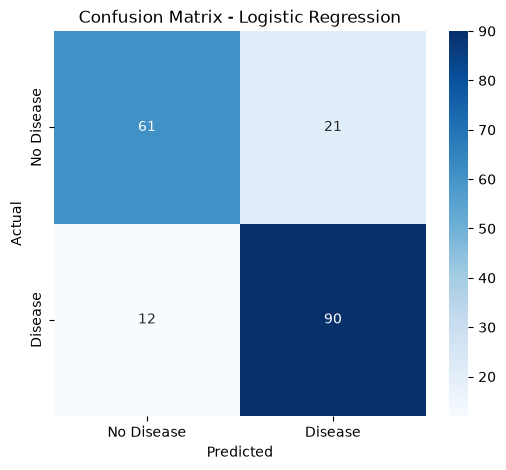

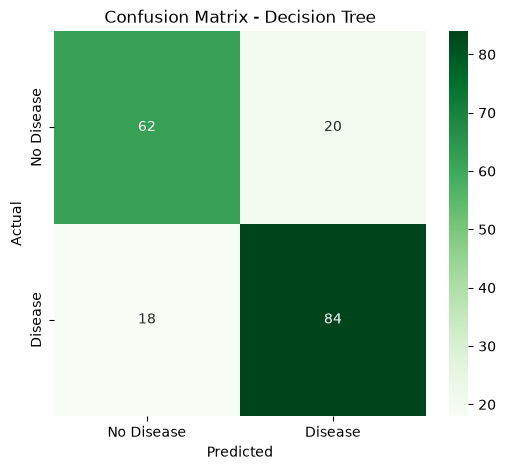

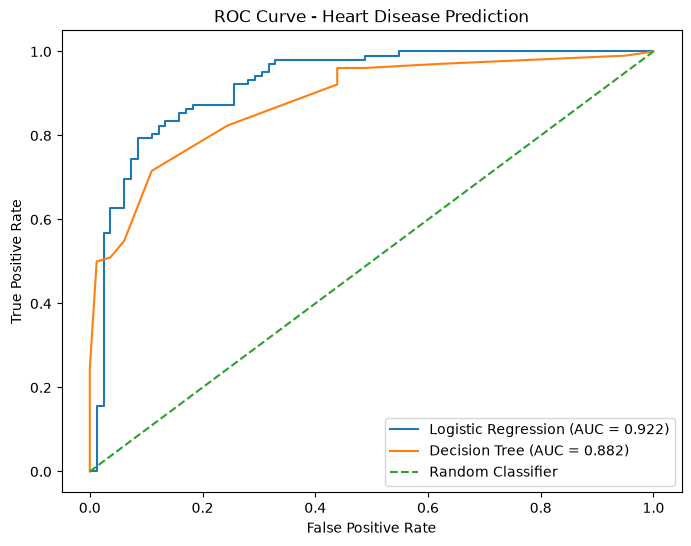


MODEL COMPARISON


,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.820652,0.810811,0.882353
1,Decision Tree,0.793478,0.807692,0.823529



WEEK 4 HEART DISEASE PREDICTION COMPLETED

Best Accuracy:
Logistic Regression

Logistic Regression AUC: 0.922
Decision Tree AUC: 0.882


In [2]:
# ============================================================
# WEEK 4 - HEART DISEASE PREDICTION
# Logistic Regression + Decision Tree
# Accuracy + Precision + Recall
# Confusion Matrix + ROC Curve
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv("heart_disease_uci.csv")

print("=" * 65)
print("HEART DISEASE PREDICTION")
print("=" * 65)

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 2. REMOVE UNNECESSARY COLUMNS
# ------------------------------------------------------------

# The UCI heart disease dataset may contain an ID column.
# Remove it if present.

for col in ["id", "ID"]:
    if col in df.columns:
        df = df.drop(columns=[col])

# ------------------------------------------------------------
# 3. FIND TARGET COLUMN
# ------------------------------------------------------------

# UCI Heart Disease dataset commonly uses "num"
# as the target column.

if "num" in df.columns:
    target = "num"
elif "target" in df.columns:
    target = "target"
elif "HeartDisease" in df.columns:
    target = "HeartDisease"
else:
    raise ValueError(
        "Target column not found. Available columns: "
        + str(df.columns.tolist())
    )

print("\nTarget Column:", target)

# ------------------------------------------------------------
# 4. CONVERT TARGET INTO BINARY CLASS
# ------------------------------------------------------------

# UCI dataset:
# num = 0  -> No heart disease
# num = 1-4 -> Heart disease

if target == "num":
    df[target] = (df[target] > 0).astype(int)

# Handle text target if necessary
elif df[target].dtype == "object":
    df[target] = df[target].astype(str).str.lower()

    mapping = {
        "no": 0,
        "yes": 1,
        "false": 0,
        "true": 1,
        "negative": 0,
        "positive": 1
    }

    df[target] = df[target].map(mapping)

# ------------------------------------------------------------
# 5. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nMissing Values:")
print(df.isnull().sum())

# ------------------------------------------------------------
# 6. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns=[target])
y = df[target]

# ------------------------------------------------------------
# 7. ENCODE CATEGORICAL FEATURES
# ------------------------------------------------------------

# Convert categorical columns into numerical values

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns

print("\nCategorical Columns:")
print(categorical_columns.tolist())

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

# ------------------------------------------------------------
# 8. HANDLE MISSING VALUES
# ------------------------------------------------------------

X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

# Make sure target has no missing values
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("\nFinal Feature Shape:", X.shape)

# ------------------------------------------------------------
# 9. TRAIN / TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# ------------------------------------------------------------
# 10. FEATURE SCALING
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")

# ============================================================
# 11. LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(
    X_test_scaled
)

logistic_prob = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

# ------------------------------------------------------------
# LOGISTIC REGRESSION METRICS
# ------------------------------------------------------------

lr_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

lr_precision = precision_score(
    y_test,
    logistic_pred,
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    logistic_pred,
    zero_division=0
)

print("\n" + "=" * 65)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 65)

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

# ============================================================
# 12. DECISION TREE
# ============================================================

tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(
    X_test
)

tree_prob = tree_model.predict_proba(
    X_test
)[:, 1]

# ------------------------------------------------------------
# DECISION TREE METRICS
# ------------------------------------------------------------

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree_precision = precision_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    tree_pred,
    zero_division=0
)

print("\n" + "=" * 65)
print("DECISION TREE RESULTS")
print("=" * 65)

print("Accuracy :", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall   :", round(tree_recall, 4))

# ============================================================
# 13. CONFUSION MATRIX - LOGISTIC REGRESSION
# ============================================================

cm_lr = confusion_matrix(
    y_test,
    logistic_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

# ============================================================
# 14. CONFUSION MATRIX - DECISION TREE
# ============================================================

cm_tree = confusion_matrix(
    y_test,
    tree_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

# ============================================================
# 15. ROC CURVE
# ============================================================

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    logistic_prob
)

roc_auc_lr = auc(
    fpr_lr,
    tpr_lr
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    tree_prob
)

roc_auc_tree = auc(
    fpr_tree,
    tpr_tree
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {roc_auc_tree:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Heart Disease Prediction")

plt.legend()
plt.show()

# ============================================================
# 16. MODEL COMPARISON
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        lr_accuracy,
        tree_accuracy
    ],
    "Precision": [
        lr_precision,
        tree_precision
    ],
    "Recall": [
        lr_recall,
        tree_recall
    ]
})

print("\n" + "=" * 65)
print("MODEL COMPARISON")
print("=" * 65)

display(results)

# ============================================================
# 17. FINAL RESULT
# ============================================================

print("\n" + "=" * 65)
print("WEEK 4 HEART DISEASE PREDICTION COMPLETED")
print("=" * 65)

print("\nBest Accuracy:")

if lr_accuracy >= tree_accuracy:
    print("Logistic Regression")
else:
    print("Decision Tree")

print("\nLogistic Regression AUC:", round(roc_auc_lr, 3))
print("Decision Tree AUC:", round(roc_auc_tree, 3))